# Image Augmentation

This notebook aims to supplement understanding of image augmentation, attempt it in PyTorch, and know how to apply it appropriately to chest X-rays.

Image augmentation creates modified versions of existing training images without requiring new labelled data. By rotating slightly, shifting slightly, zooming in and out, and adjusting its brightness and contrast, image augmentation helps the model learn patterns that generalise beyond the exact images it had seen during training, thus reducing overfitting.

It is crucial to apply image augmentation to training data only. Validation and test data should not be augmented, so that the model's performance evaluation can still be done on the original data distribution.

** Important Note:
For Chest Xrays and medical imaging, avoid aggressive transformations. In particular, don't apply vertical or horizontal flips without considering anatomical laterality and clinical significance.

## PyTorch: torchvision.transforms

PyTorch offers a library of ready-made image transformations, including RandomRotation, RandomAffine, RandomHorizontalFlip, ColorJitter, RandomResizedCrop.

torchvision.transforms lets you compose individual transformations

In [ ]:
import torch
from torchvision import transforms

# Image Transform
train_transform = transforms.Compose([
    transforms.RandomAffine(
        degrees=5,   #randomly rotate up to 5 degrees in either direction
        translate=(0.03, 0.03),   #shifts image by up to 3% horizontally and vertically
        scale=(0.95, 1.05))])   #randomly scales image between 95-105%

# Create dummy grayscale image
image = torch.randn(1, 64, 64)

# Apply augmentation
augmented_image = train_transform(image)

# Results
print("Original:", image.shape)
print("Augmented:", augmented_image.shape)

Original: torch.Size([1, 64, 64])
Augmented: torch.Size([1, 64, 64])


## fast.ai: aug_transforms

fast.ai provides a higher-level function that bundles several augmentation techniques.

fast.ai's aug_transforms conveniently combines transformations

In [ ]:
from fastai.vision.augment import aug_transforms

item_tfms = aug_transforms(
    max_rotate=5,
    max_zoom=1.05,
    max_warp=0,  #max image distortion
    max_lighting=0.1,  #brightness/contrast variation
    do_flip=False)  #whether to use horizontal flip

# When using DataBlock, use batch_tfms instead
dblock = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    batch_tfms=aug_transforms(
        max_rotate=5,
        max_zoom=1.05,
        max_warp=0,
        max_lighting=0.1,
        do_flip=False))

ModuleNotFoundError: No module named 'fastai'

## Practical Exercise

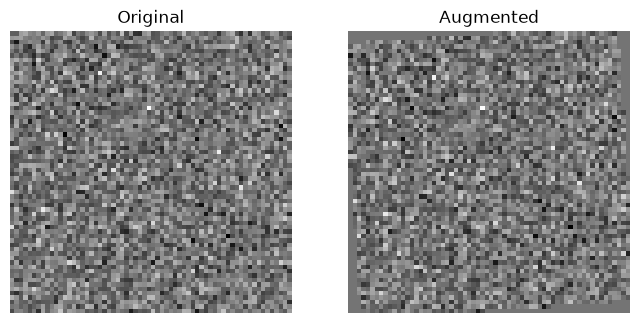

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(image.squeeze(), cmap="gray")
axes[0].set_title("Original")
axes[1].imshow(augmented_image.squeeze(), cmap="gray")
axes[1].set_title("Augmented")

for ax in axes:
    ax.axis("off")
plt.show()